<a href="https://colab.research.google.com/github/LizaMilovanova/Labs/blob/main/%D0%9B%D0%A0_4_%D0%9C%D1%96%D0%BB%D0%BE%D0%B2%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_%D0%A4%D0%86%D0%A24_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [5]:
import os
import kagglehub
import pandas as pd

# Завантаження останньої версії датасету з Kaggle
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
print("Шлях до завантажених файлів:", path)

# Пошук потрібного CSV-файлу в завантаженій папці та зчитування в DataFrame
csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]
csv_path = os.path.join(path, "CarPrice_Assignment.csv")

df = pd.read_csv(csv_path)

# Перегляд перших рядків
df.head()

100%|██████████| 18.1k/18.1k [00:00<00:00, 18.2MB/s]

Extracting files...
Шлях до завантажених файлів: /root/.cache/kagglehub/datasets/hellbuoy/car-price-prediction/versions/1


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [8]:
# Визначення кількості об'єктів та ознак
df.shape

(205, 26)

In [11]:
# Перегляд назв стовпців
df.columns

Index(['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration',
       'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase',
       'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype',
       'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg',
       'price'],
      dtype='object')

In [12]:
# Визначення типів даних та наявності пропусків
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [13]:
# Визначення цільової змінної
target = 'price'
print(f"\nЦільова змінна для регресії: '{target}'")
print(f"Тип цільової змінної: {df[target].dtype}")


Цільова змінна для регресії: 'price'
Тип цільової змінної: float64


In [14]:
# 6. Виведення основних статистичних характеристик
print("\nОписова статистика числових ознак")
display(df.describe())

print("\nОписова статистика категоріальних ознак")
display(df.describe(include=['object']))


Описова статистика числових ознак


,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000



Описова статистика категоріальних ознак


,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,enginetype,cylindernumber,fuelsystem
count,205,205,205,205,205,205,205,205,205,205
unique,147,2,2,2,5,3,2,7,7,8
top,peugeot 504,gas,std,four,sedan,fwd,front,ohc,four,mpfi
freq,6,185,168,115,96,120,202,148,159,94


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [16]:
# Перевірка наявності пропущених значень
df.isnull().sum()

,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


In [18]:
# Перевірка наявності дублікатів
df.duplicated().sum()

np.int64(0)

In [19]:
# Кількість унікальних значень у кожній ознаці
unique_counts = df.nunique()
print(unique_counts)

car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight          171
enginetype            7
cylindernumber        7
enginesize           44
fuelsystem            8
boreratio            38
stroke               37
compressionratio     32
horsepower           59
peakrpm              23
citympg              29
highwaympg           30
price               189
dtype: int64


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [20]:
# Зберігаємо ідентифікатори в окрему серію/масив для подальшої прив'язки прогнозів
car_ids = df['car_ID'].copy()

# Видаляємо car_ID з робочого датафрейму
df = df.drop(columns=['car_ID'])

print(f"car_ID успішно збережено окремо. Кількість ID: {len(car_ids)}")
print(f"Форма датасету після видалення car_ID: {df.shape}")

car_ID успішно збережено окремо. Кількість ID: 205
Форма датасету після видалення car_ID: (205, 25)


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Відбір числових ознак
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"Числові ознаки ({len(numeric_cols)}): {numeric_cols}\n")

Числові ознаки (15): ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']



In [22]:
# Розрахунок коефіцієнтів асиметрії (Skewness)
skewness = df[numeric_cols].skew().sort_values(ascending=False)
skew_df = pd.DataFrame({
    'Ознака': skewness.index,
    'Коефіцієнт асиметрії (Skewness)': skewness.values
})

print("Коефіцієнти асиметрії ознак (від найбільшого)")
display(skew_df)

# Ознаки з вираженою правосторонньою або лівосторонньою асиметрією (|skew| > 1)
high_skew = skew_df[skew_df['Коефіцієнт асиметрії (Skewness)'].abs() > 1]
print("\nОзнаки з найбільш вираженою асиметрією (|skew| > 1)")
display(high_skew)

Коефіцієнти асиметрії ознак (від найбільшого)


,Ознака,Коефіцієнт асиметрії (Skewness)
0,compressionratio,2.610862
1,enginesize,1.947655
2,price,1.777678
3,horsepower,1.405310
4,wheelbase,1.050214
5,carwidth,0.904003
6,curbweight,0.681398
7,citympg,0.663704
8,highwaympg,0.539997
9,symboling,0.211072



Ознаки з найбільш вираженою асиметрією (|skew| > 1)


,Ознака,Коефіцієнт асиметрії (Skewness)
0,compressionratio,2.610862
1,enginesize,1.947655
2,price,1.777678
3,horsepower,1.405310
4,wheelbase,1.050214


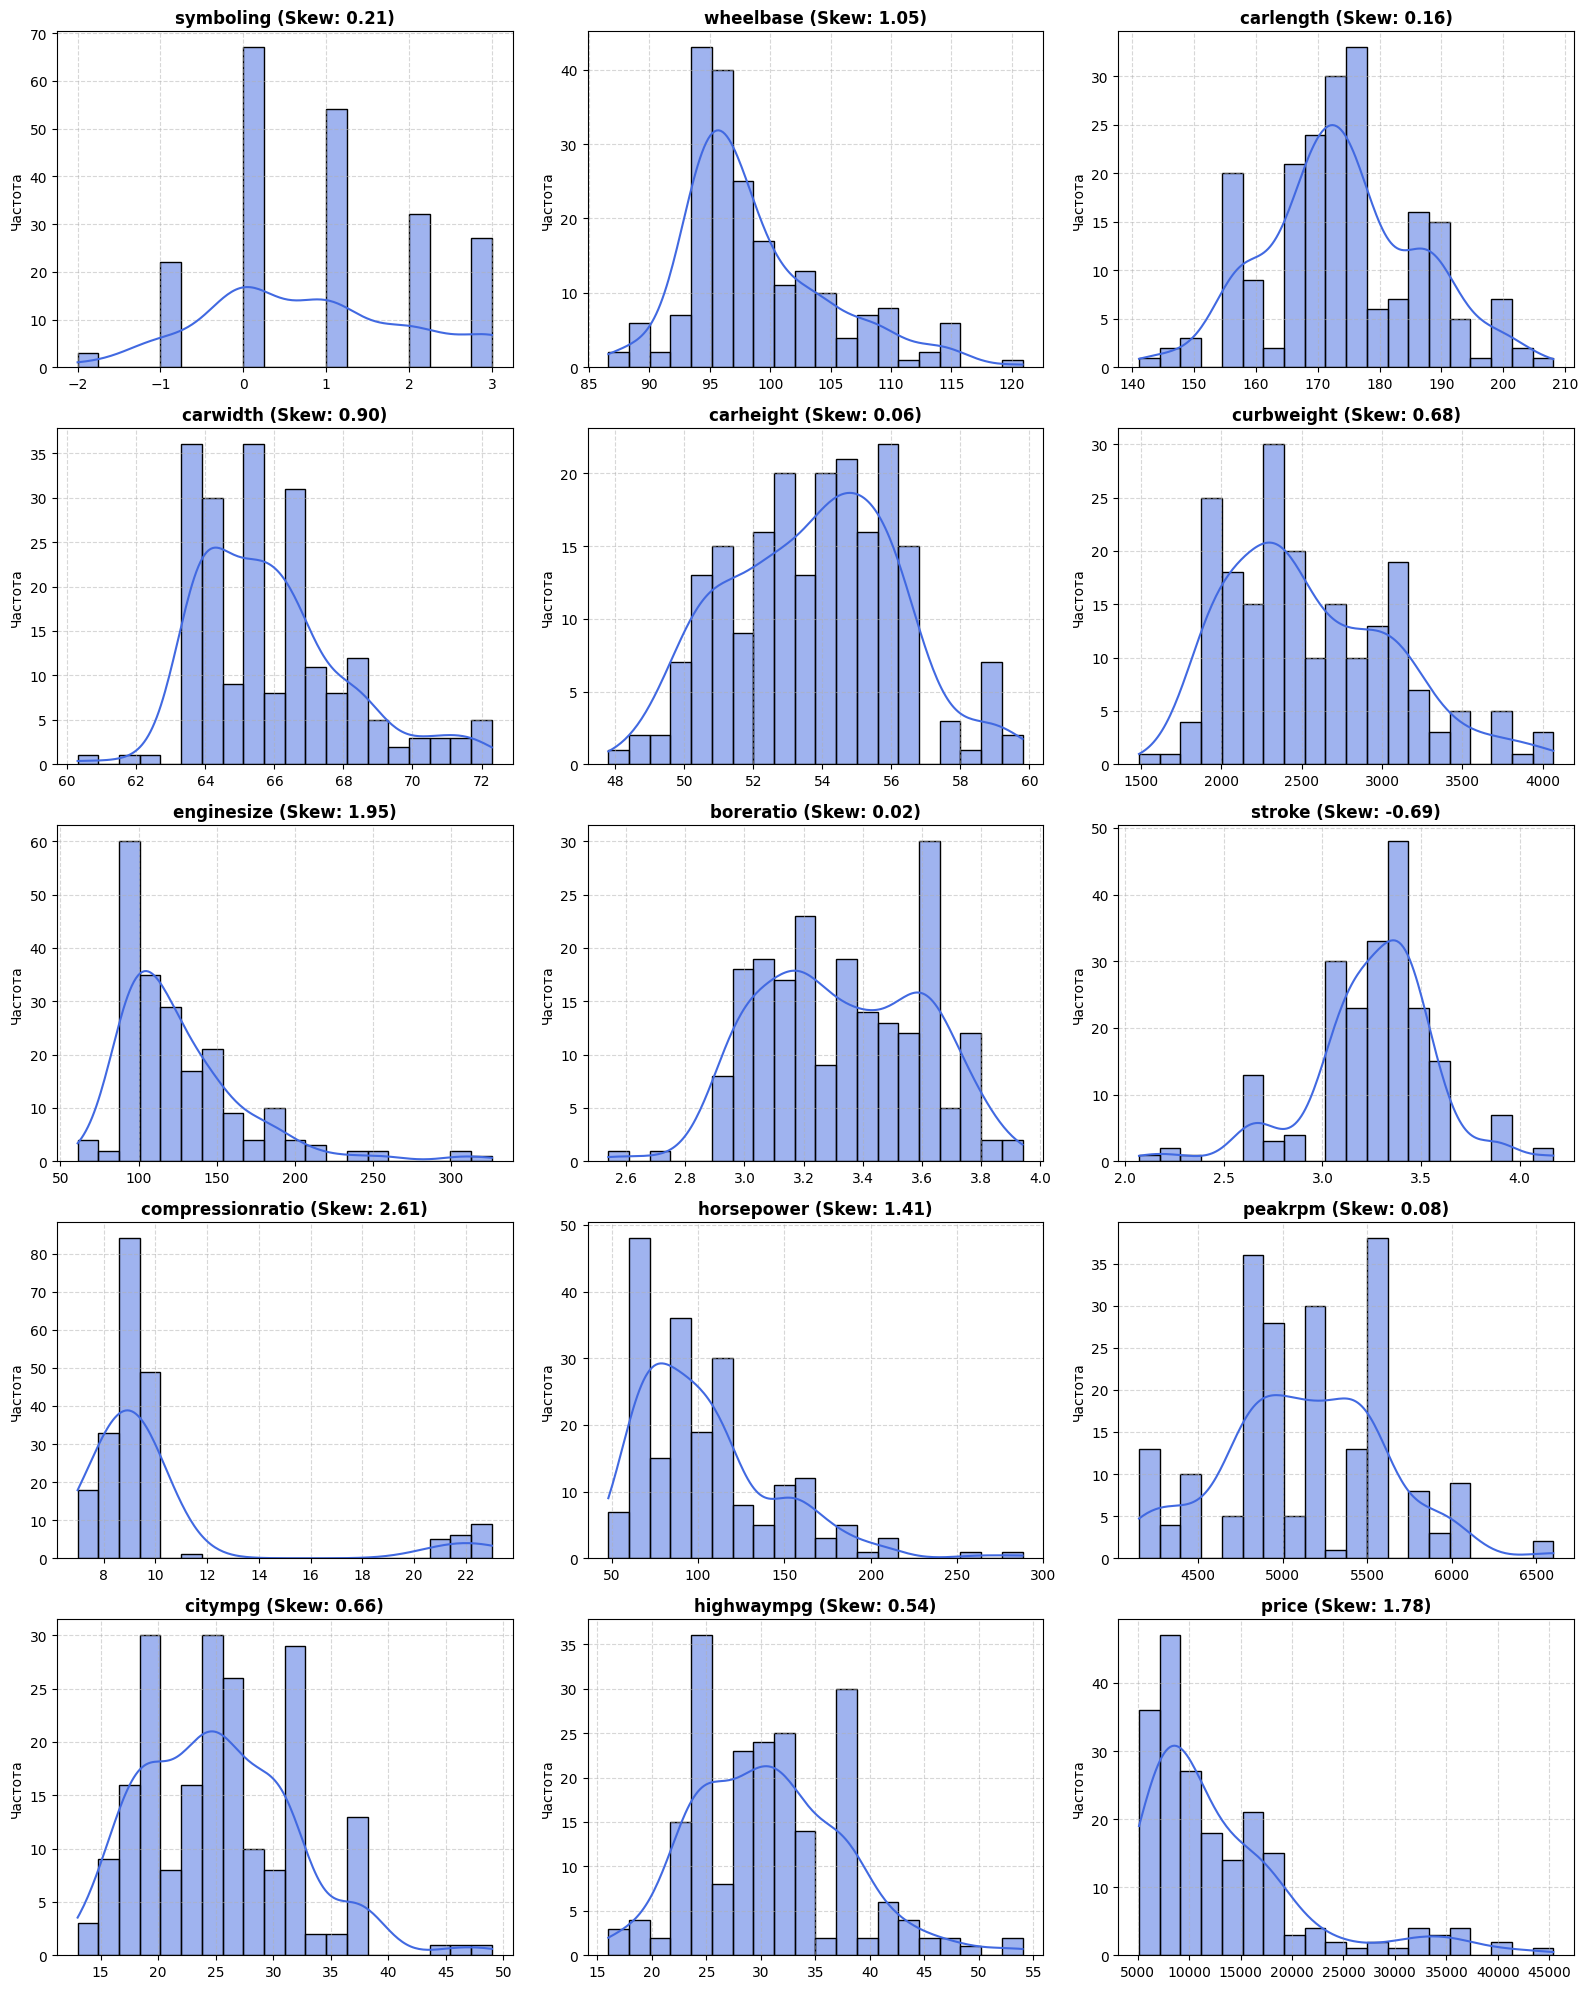

In [23]:
# Побудова графіків розподілу (гістограми + лінія щільності KDE)
n_cols = 3
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for idx, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[idx], color='royalblue', bins=20)
    skew_val = df[col].skew()
    axes[idx].set_title(f"{col} (Skew: {skew_val:.2f})", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel('Частота')
    axes[idx].grid(True, linestyle='--', alpha=0.5)

# Приховуємо зайві підграфіки, якщо кількість колонок не ділиться на 3
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Цільова змінна (price) та потужні параметри двигуна (enginesize, horsepower):
1. Мають виражену правосторонню (додатну) асиметрію (Skew>1.5).

Пояснення: Більшість автомобілів на ринку належать до бюджетного та середнього цінового сегментів, тоді як невелика кількість преміальних та спорткарів формує довгий «правий хвіст» розподілу. Для лінійних моделей у подальшому може бути корисним логарифмування ціни (np.log1p(df['price'])).

2. Габаритні показники (curbweight, carlength, carwidth, wheelbase):
Мають помірну додатну асиметрію (0<Skew<1), розподіли є ближчими до нормального (дзвоноподібного).

3. Економічність (citympg, highwaympg):
Також мають додатне скошення через наявність окремих надзвичайно економних малолітражних/дизельних авто.

4. Параметри compressionratio:
Має високу асиметрію через специфіку дизельних двигунів, у яких ступінь стиснення значно вищий, ніж у бензинових (формує окремий виокремлений пік/викиди).

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [24]:
from sklearn.model_selection import train_test_split

# 1. Відокремлюємо цільову змінну 'price' від матриці ознак X
y = df['price']
X = df.drop(columns=['price'])

# 2. Поділ на навчальну (80%) та тестову (20%) вибірки
# Одночасно передаємо car_ids, щоб отримати відповідні ID для train та test
# random_state=42 забезпечує повну відтворюваність результатів поділу
X_train, X_test, y_train, y_test, car_id_train, car_id_test = train_test_split(
    X,
    y,
    car_ids,
    test_size=0.20,
    random_state=42
)

# 3. Виведення інформації про отримані вибірки
print("Розміри отриманих вибірок")
print(f"Ознаки для навчання (X_train): {X_train.shape}")
print(f"Цільова змінна для навчання (y_train): {y_train.shape}")
print(f"Ідентифікатори car_ID (train): {car_id_train.shape[0]}")
print(f"Ознаки для тесту (X_test): {X_test.shape}")
print(f"Цільова змінна для тесту (y_test): {y_test.shape}")
print(f"Ідентифікатори car_ID (test): {car_id_test.shape[0]}")

# Перевірка відсоткового співвідношення
total_samples = len(df)
print(f"\nЧастка train: {len(X_train) / total_samples:.1%}")
print(f"Частка test:  {len(X_test) / total_samples:.1%}")

--- Розміри отриманих вибірок ---
Ознаки для навчання (X_train): (164, 24)
Цільова змінна для навчання (y_train): (164,)
Ідентифікатори car_ID (train): 164
---
Ознаки для тесту (X_test): (41, 24)
Цільова змінна для тесту (y_test): (41,)
Ідентифікатори car_ID (test): 41

Частка train: 80.0%
Частка test:  20.0%


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [26]:
import numpy as np

# 1. Відбираємо неперервні числові ознаки навчальної вибірки (X_train)
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()

# Створюємо копії вибірок для збереження результатів обробки
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

iqr_summary = []
bounds = {}

# 2. Розрахунок меж IQR для кожної числової ознаки на train
for col in numeric_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Зберігаємо межі навчальної вибірки
    bounds[col] = (lower_bound, upper_bound)

    # Підрахунок кількості потенційних викидів у train
    outliers_count = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    outliers_pct = (outliers_count / len(X_train)) * 100

    iqr_summary.append({
        'Ознака': col,
        'Q1 (25%)': round(Q1, 2),
        'Q3 (75%)': round(Q3, 2),
        'IQR': round(IQR, 2),
        'Нижня межа': round(lower_bound, 2),
        'Верхня межа': round(upper_bound, 2),
        'Викидів (train)': outliers_count,
        'Частка (%)': round(outliers_pct, 2)
    })

outliers_df = pd.DataFrame(iqr_summary).sort_values(by='Викидів (train)', ascending=False)

print("Кількість потенційних викидів за методом IQR у train")
display(outliers_df)

# 3. Обробка викидів: clipping (вінзоризація) межами з train
# Застосовуємо однакові межі до X_train та X_test
for col in numeric_features:
    low, high = bounds[col]
    X_train_clean[col] = X_train_clean[col].clip(lower=low, upper=high)
    X_test_clean[col] = X_test_clean[col].clip(lower=low, upper=high)

# Оновлюємо робочі змінні
X_train = X_train_clean
X_test = X_test_clean

print("\nОбробку викидів завершено (використано метод clipping за межами IQR train).")
print(f"Розмір X_train після обробки: {X_train.shape} (кількість рядків не зменшилась)")
print(f"Розмір X_test після обробки: {X_test.shape}")

Кількість потенційних викидів за методом IQR у train


,Ознака,Q1 (25%),Q3 (75%),IQR,Нижня межа,Верхня межа,Викидів (train),Частка (%)
0,symboling,0.00,2.00,2.00,-3.00,5.00,0,0.0
1,wheelbase,94.50,102.10,7.60,83.10,113.50,0,0.0
2,carlength,166.68,183.20,16.52,141.89,207.99,0,0.0
3,carwidth,64.18,66.68,2.50,60.42,70.42,0,0.0
4,carheight,51.90,55.52,3.62,46.46,60.96,0,0.0
5,curbweight,2163.00,2939.25,776.25,998.62,4103.62,0,0.0
6,enginesize,98.00,141.00,43.00,33.50,205.50,0,0.0
7,boreratio,3.15,3.54,0.39,2.56,4.12,0,0.0
8,stroke,3.11,3.41,0.30,2.66,3.86,0,0.0
9,compressionratio,8.60,9.40,0.80,7.40,10.60,0,0.0



Обробку викидів завершено (використано метод clipping за межами IQR train).
Розмір X_train після обробки: (164, 24) (кількість рядків не зменшилась)
Розмір X_test після обробки: (41, 24)


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


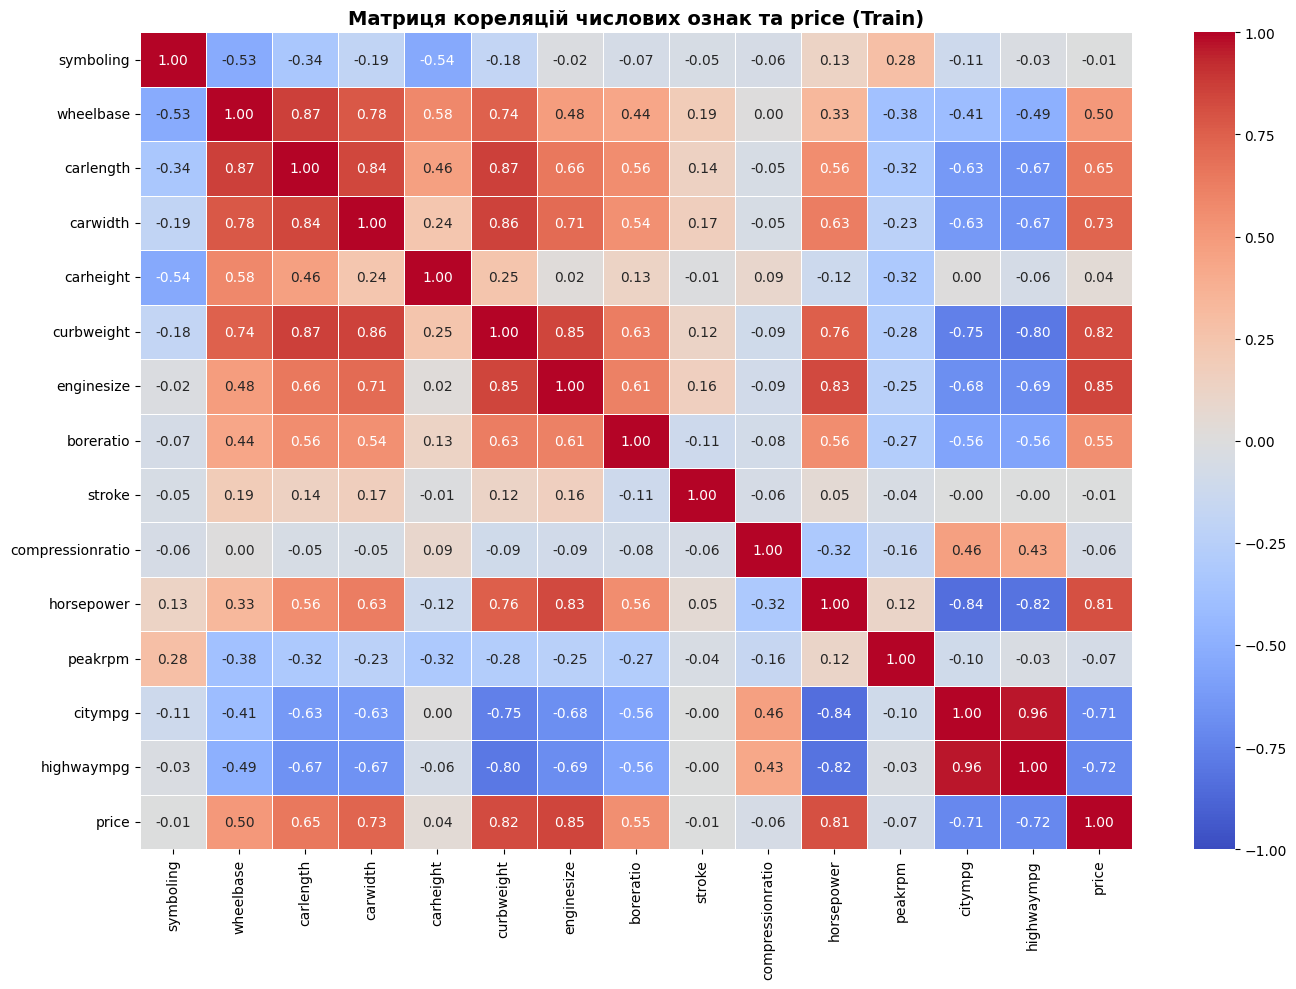

Сильно корельовані пари ознак (|r| > 0.85) та прийняті рішення


,Ознака 1,Ознака 2,Кореляція між собою (r),|r| wheelbase до price,|r| carlength до price,Залишаємо,Видаляємо,|r| curbweight до price,|r| carwidth до price,|r| citympg до price,|r| highwaympg до price
0,wheelbase,carlength,0.867,0.504,0.652,carlength,wheelbase,NaN,NaN,NaN,NaN
1,carlength,curbweight,0.866,NaN,0.652,curbweight,carlength,0.824,NaN,NaN,NaN
2,carwidth,curbweight,0.858,NaN,NaN,curbweight,carwidth,0.824,0.732,NaN,NaN
3,citympg,highwaympg,0.964,NaN,NaN,highwaympg,citympg,NaN,NaN,0.711,0.716



Перелік ознак, що видаляються через мультиколінеарність (4 шт.)
['carwidth', 'carlength', 'citympg', 'wheelbase']

Результат оновлення вибірок
Форма X_train після відбору ознак: (164, 20)
Форма X_test після відбору ознак:  (41, 20)


In [27]:
# 1. Відбираємо числові ознаки з X_train
numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

# Об'єднуємо числові ознаки train із y_train виключно для кореляційного аналізу
train_numeric_data = X_train[numeric_cols].copy()
train_numeric_data['price'] = y_train

# Обчислюємо матрицю кореляцій Пірсона за навчальною вибіркою
corr_matrix = train_numeric_data.corr()

# Побудова теплової карти (Heatmap)
plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title("Матриця кореляцій числових ознак та price (Train)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Пошук пар із сильною кореляцією (|r| > 0.85) між предикторами
threshold = 0.85
feature_corr = X_train[numeric_cols].corr()

# Кореляція кожної ознаки з цільовою змінною price
target_corr = corr_matrix['price'].drop('price')

cols_to_drop = set()
correlated_pairs = []

# Аналізуємо верхній трикутник матриці кореляцій ознак
for i in range(len(numeric_cols)):
    for j in range(i + 1, len(numeric_cols)):
        col_a = numeric_cols[i]
        col_b = numeric_cols[j]
        r_ab = feature_corr.loc[col_a, col_b]

        if abs(r_ab) > threshold:
            r_target_a = abs(target_corr[col_a])
            r_target_b = abs(target_corr[col_b])

            # Залишаємо ознаку з вищою кореляцією до price, іншу вилучаємо
            if r_target_a >= r_target_b:
                keep = col_a
                drop = col_b
            else:
                keep = col_b
                drop = col_a

            cols_to_drop.add(drop)

            correlated_pairs.append({
                'Ознака 1': col_a,
                'Ознака 2': col_b,
                'Кореляція між собою (r)': round(r_ab, 3),
                f'|r| {col_a} до price': round(r_target_a, 3),
                f'|r| {col_b} до price': round(r_target_b, 3),
                'Залишаємо': keep,
                'Видаляємо': drop
            })

pairs_df = pd.DataFrame(correlated_pairs)

print("Сильно корельовані пари ознак (|r| > 0.85) та прийняті рішення")
display(pairs_df)

print(f"\nПерелік ознак, що видаляються через мультиколінеарність ({len(cols_to_drop)} шт.)")
print(list(cols_to_drop))

# 3. Видалення відібраних ознак з навчальної та тестової вибірок
X_train = X_train.drop(columns=list(cols_to_drop))
X_test = X_test.drop(columns=list(cols_to_drop))

print("\nРезультат оновлення вибірок")
print(f"Форма X_train після відбору ознак: {X_train.shape}")
print(f"Форма X_test після відбору ознак:  {X_test.shape}")

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder

# 1. Розподіл ознак на групи
# Дискретна числова ознака
discrete_feature = ['symboling'] if 'symboling' in X_train.columns else []

# Категоріальні ознаки (текстові / object)
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

# Неперервні числові ознаки (числові за винятком 'symboling')
continuous_features = [
    col for col in X_train.select_dtypes(include=[np.number]).columns
    if col not in discrete_feature
]

print(f"Неперервні числові ознаки ({len(continuous_features)}): {continuous_features}")
print(f"Дискретна ознака: {discrete_feature}")
print(f"Категоріальні ознаки ({len(categorical_features)}): {categorical_features}\n")

# 2. Побудова пайплайнів обробки для кожної групи ознак

# А) Пайплайн для неперервних числових: Yeo-Johnson -> StandardScaler
continuous_pipeline = Pipeline([
    ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

# Б) Пайплайн для symboling: тільки StandardScaler
discrete_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

# В) Пайплайн для категоріальних: One-Hot Encoding з handle_unknown='ignore'
categorical_pipeline = Pipeline([
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 3. Об'єднання всіх перетворень у єдиний ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num_cont', continuous_pipeline, continuous_features),
        ('num_disc', discrete_pipeline, discrete_feature),
        ('cat', categorical_pipeline, categorical_features)
    ],
    remainder='drop'
)

# 4. Навчання трансформера тільки на X_train та перетворення вибірок
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

# Отримання назв трансформованих ознак для зручності аналізу
transformed_feature_names = preprocessor.get_feature_names_out()

# Перетворення результатів у DataFrame зі збереженням індексів
X_train_ready = pd.DataFrame(
    X_train_preprocessed,
    columns=transformed_feature_names,
    index=X_train.index
)
X_test_ready = pd.DataFrame(
    X_test_preprocessed,
    columns=transformed_feature_names,
    index=X_test.index
)

print(f"Розмірність матриці ознак X_train після обробки: {X_train_ready.shape}")
print(f"Розмірність матриці ознак X_test після обробки:  {X_test_ready.shape}")
print("\nПерші 3 рядки підготовленого набору train:")
display(X_train_ready.head(3))

Неперервні числові ознаки (9): ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна ознака: ['symboling']
Категоріальні ознаки (10): ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']

Розмірність матриці ознак X_train після обробки: (164, 171)
Розмірність матриці ознак X_test після обробки:  (41, 171)

Перші 3 рядки підготовленого набору train:


,num_cont__carheight,num_cont__curbweight,num_cont__enginesize,num_cont__boreratio,num_cont__stroke,num_cont__compressionratio,num_cont__horsepower,num_cont__peakrpm,num_cont__highwaympg,num_disc__symboling,...,cat__cylindernumber_twelve,cat__cylindernumber_two,cat__fuelsystem_1bbl,cat__fuelsystem_2bbl,cat__fuelsystem_4bbl,cat__fuelsystem_idi,cat__fuelsystem_mfi,cat__fuelsystem_mpfi,cat__fuelsystem_spdi,cat__fuelsystem_spfi
66,0.283461,0.455778,0.540306,0.419807,1.470292,1.998322,-0.962378,-1.944939,1.291931,-0.72738,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
111,1.203945,1.063079,0.101671,0.529800,-2.022836,-0.845060,0.010873,-0.285652,-1.034713,-0.72738,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
153,2.151912,-0.439830,-1.147848,-1.009773,-0.884725,-0.057773,-1.559900,-0.696264,1.011557,-0.72738,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


Порівняння коефіцієнтів асиметрії до та після перетворення


,Ознака,Skewness (До),Skewness (Після),Зміна (|Δ|)
0,carheight,0.028,-0.005,0.023
1,curbweight,0.712,0.050,0.663
2,enginesize,0.962,0.045,0.918
3,boreratio,0.063,-0.006,0.057
4,stroke,-0.398,0.016,0.382
5,compressionratio,0.056,0.005,0.051
6,horsepower,0.851,0.066,0.784
7,peakrpm,0.040,-0.004,0.036
8,highwaympg,0.244,-0.012,0.232


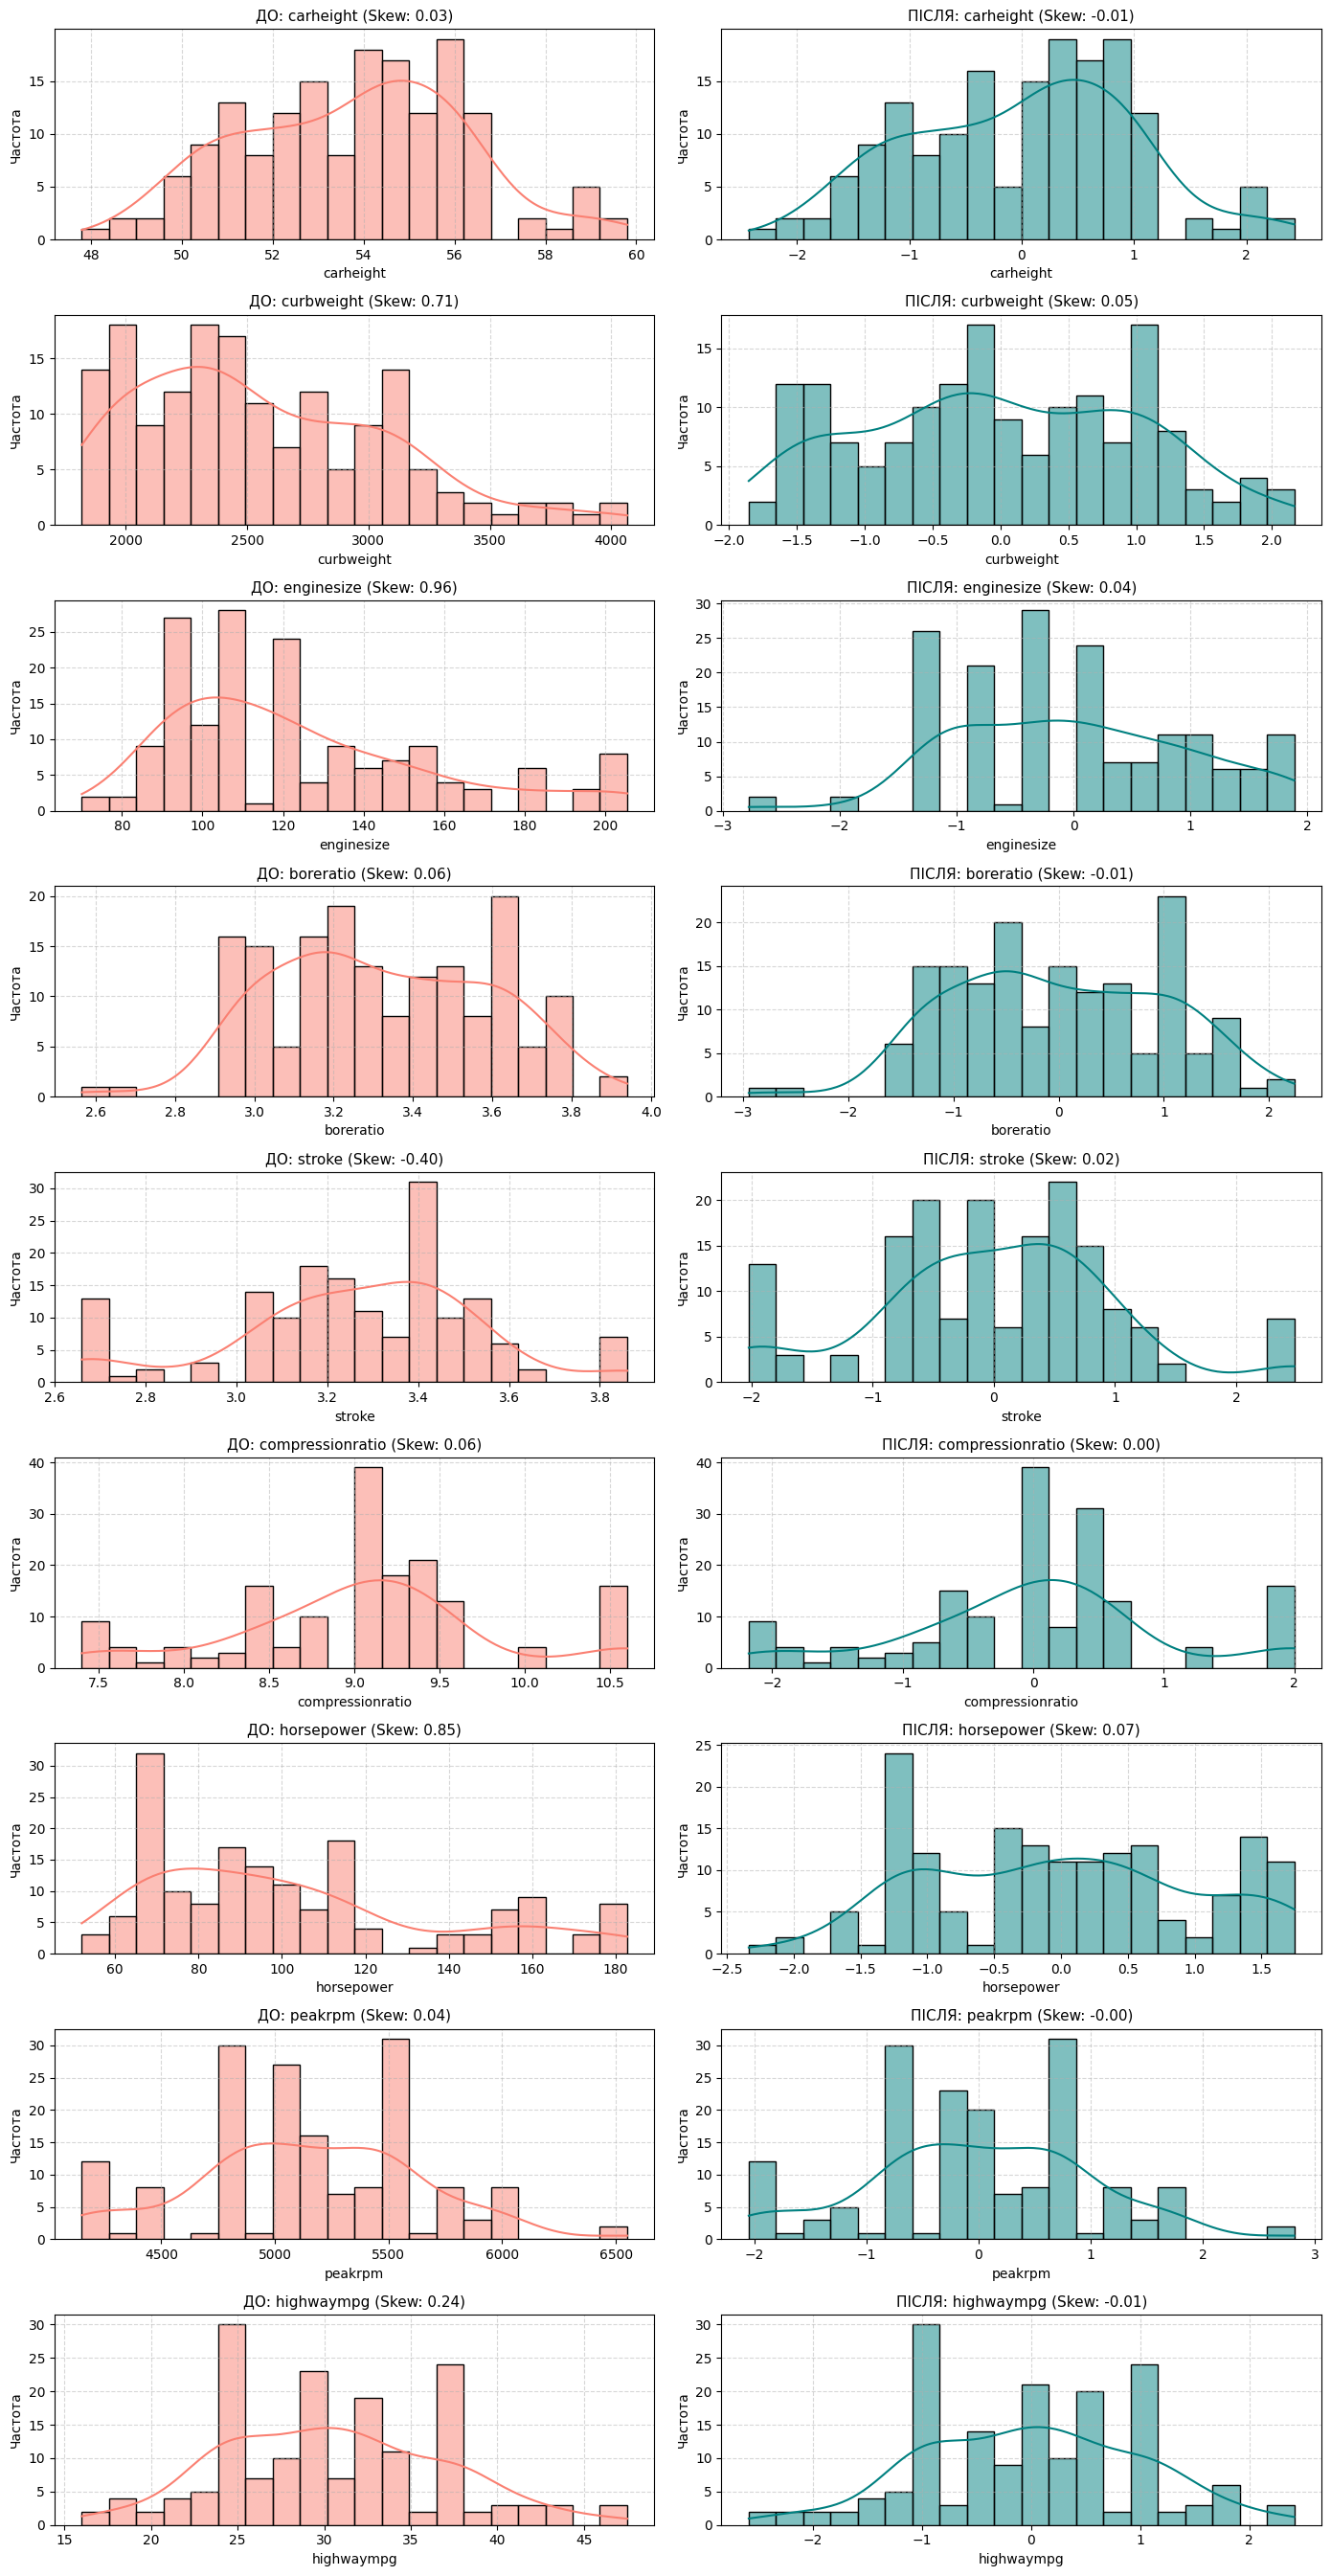

In [29]:
# 1. Застосовуємо пайплайн перетворень (Yeo-Johnson + StandardScaler) до train
X_cont_transformed = continuous_pipeline.fit_transform(X_train[continuous_features])
df_cont_transformed = pd.DataFrame(
    X_cont_transformed,
    columns=continuous_features,
    index=X_train.index
)

# 2. Обчислюємо асиметрію до та після трансформації
skew_before = X_train[continuous_features].skew()
skew_after = df_cont_transformed.skew()

# 3. Порівняльна таблиця
comparison_df = pd.DataFrame({
    'Ознака': continuous_features,
    'Skewness (До)': skew_before.round(3),
    'Skewness (Після)': skew_after.round(3),
    'Зміна (|Δ|)': (skew_before.abs() - skew_after.abs()).round(3)
}).reset_index(drop=True)

print("Порівняння коефіцієнтів асиметрії до та після перетворення")
display(comparison_df)

# 4. Графічне порівняння розподілів (До vs Після)
n_features = len(continuous_features)
fig, axes = plt.subplots(nrows=n_features, ncols=2, figsize=(14, 3 * n_features))

for i, col in enumerate(continuous_features):
    # До трансформації
    sns.histplot(X_train[col], kde=True, ax=axes[i, 0], color='salmon', bins=20)
    axes[i, 0].set_title(f"ДО: {col} (Skew: {skew_before[col]:.2f})", fontsize=11)
    axes[i, 0].set_ylabel('Частота')
    axes[i, 0].grid(True, linestyle='--', alpha=0.5)

    # Після трансформації
    sns.histplot(df_cont_transformed[col], kde=True, ax=axes[i, 1], color='teal', bins=20)
    axes[i, 1].set_title(f"ПІСЛЯ: {col} (Skew: {skew_after[col]:.2f})", fontsize=11)
    axes[i, 1].set_ylabel('Частота')
    axes[i, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [32]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
# Словник базових моделей із фіксацією random_state для відтворюваності
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0, random_state=42),
    'Lasso Regression': Lasso(alpha=1.0, random_state=42),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'Support Vector Regressor (SVR)': SVR(kernel='rbf', C=100.0, epsilon=0.1)
}

# Створюємо та навчаємо єдиний Pipeline для кожної моделі
# Використовується однакова схема передобробки (preprocessor з пункту 8)
pipelines = {}

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

    # Навчання пайплайна суворо на вхідних ознаках X_train та цільовій змінній y_train
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    print(f"✓ Модель '{name}' успішно побудована та навчена.")

print("\nУсі 6 моделей готові для оцінки метрик та порівняння.")

✓ Модель 'Linear Regression' успішно побудована та навчена.
✓ Модель 'Ridge Regression' успішно побудована та навчена.
✓ Модель 'Lasso Regression' успішно побудована та навчена.
✓ Модель 'Random Forest Regressor' успішно побудована та навчена.
✓ Модель 'Gradient Boosting Regressor' успішно побудована та навчена.
✓ Модель 'Support Vector Regressor (SVR)' успішно побудована та навчена.

Усі 6 моделей готові для оцінки метрик та порівняння.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [33]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

results = []

# Цикл по кожній побудованій моделі/пайплайну
for name, pipe in pipelines.items():
    # 1. Навчання моделі на навчальній вибірці (якщо вже навчено в п.10, цей виклик гарантує актуальність)
    pipe.fit(X_train, y_train)

    # 2. Отримання прогнозів для тестової вибірки
    y_pred = pipe.predict(X_test)

    # 3. Обчислення метрик якості
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100  # подаємо у відсотках

    results.append({
        'Модель': name,
        'R²': r2,
        'MAE': mae,
        'MSE': mse,
        'MAPE (%)': mape
    })

# 4. Об'єднання в одну таблицю та сортування за R² від найбільшого до найменшого
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='R²', ascending=False).reset_index(drop=True)

# Форматування для зручного та наочного виведення
styled_results = results_df.style.format({
    'R²': '{:.4f}',
    'MAE': '{:,.2f}',
    'MSE': '{:,.2f}',
    'MAPE (%)': '{:.2f}%'
}).highlight_max(subset=['R²'], color='lightgreen') \
  .highlight_min(subset=['MAE', 'MSE', 'MAPE (%)'], color='lightgreen')

display(styled_results)

,Модель,R²,MAE,MSE,MAPE (%)
0,Random Forest Regressor,0.9494,"1,447.34","3,996,761.37",10.36%
1,Gradient Boosting Regressor,0.9291,"1,703.69","5,596,688.22",12.64%
2,Ridge Regression,0.7957,"2,712.77","16,129,423.33",23.07%
3,Lasso Regression,0.7061,"3,088.99","23,202,797.20",22.61%
4,Linear Regression,0.5481,"4,078.23","35,676,914.46",29.97%
5,Support Vector Regressor (SVR),0.1075,"4,578.15","70,456,877.60",25.86%


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Чому не підходить Logistic Regression:

1. Різні типи виходу: Логістична регресія — це модель класифікації, яка прогнозує дискретні категорії або ймовірність належності до класу від 0 до 1, а не конкретну грошову суму.

2. Природа ціни: Вартість авто (price) — це неперервне числове значення, яке не має фіксованого діапазону та кількості класів.

До якого типу належить задача та чому обрані ці моделі:

1. Тип задачі: Регресія (навчання з учителем), оскільки метою є прогнозування конкретного числового значення на неперервній шкалі.

2. Відповідність моделей: Усі використані моделі (Linear, Ridge, Lasso, Random Forest, Gradient Boosting, SVR) розроблені спеціально для регресії: вони мінімізують величину числової похибки (наприклад, MSE чи MAE) та видають прогноз у вигляді реальної вартості авто.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


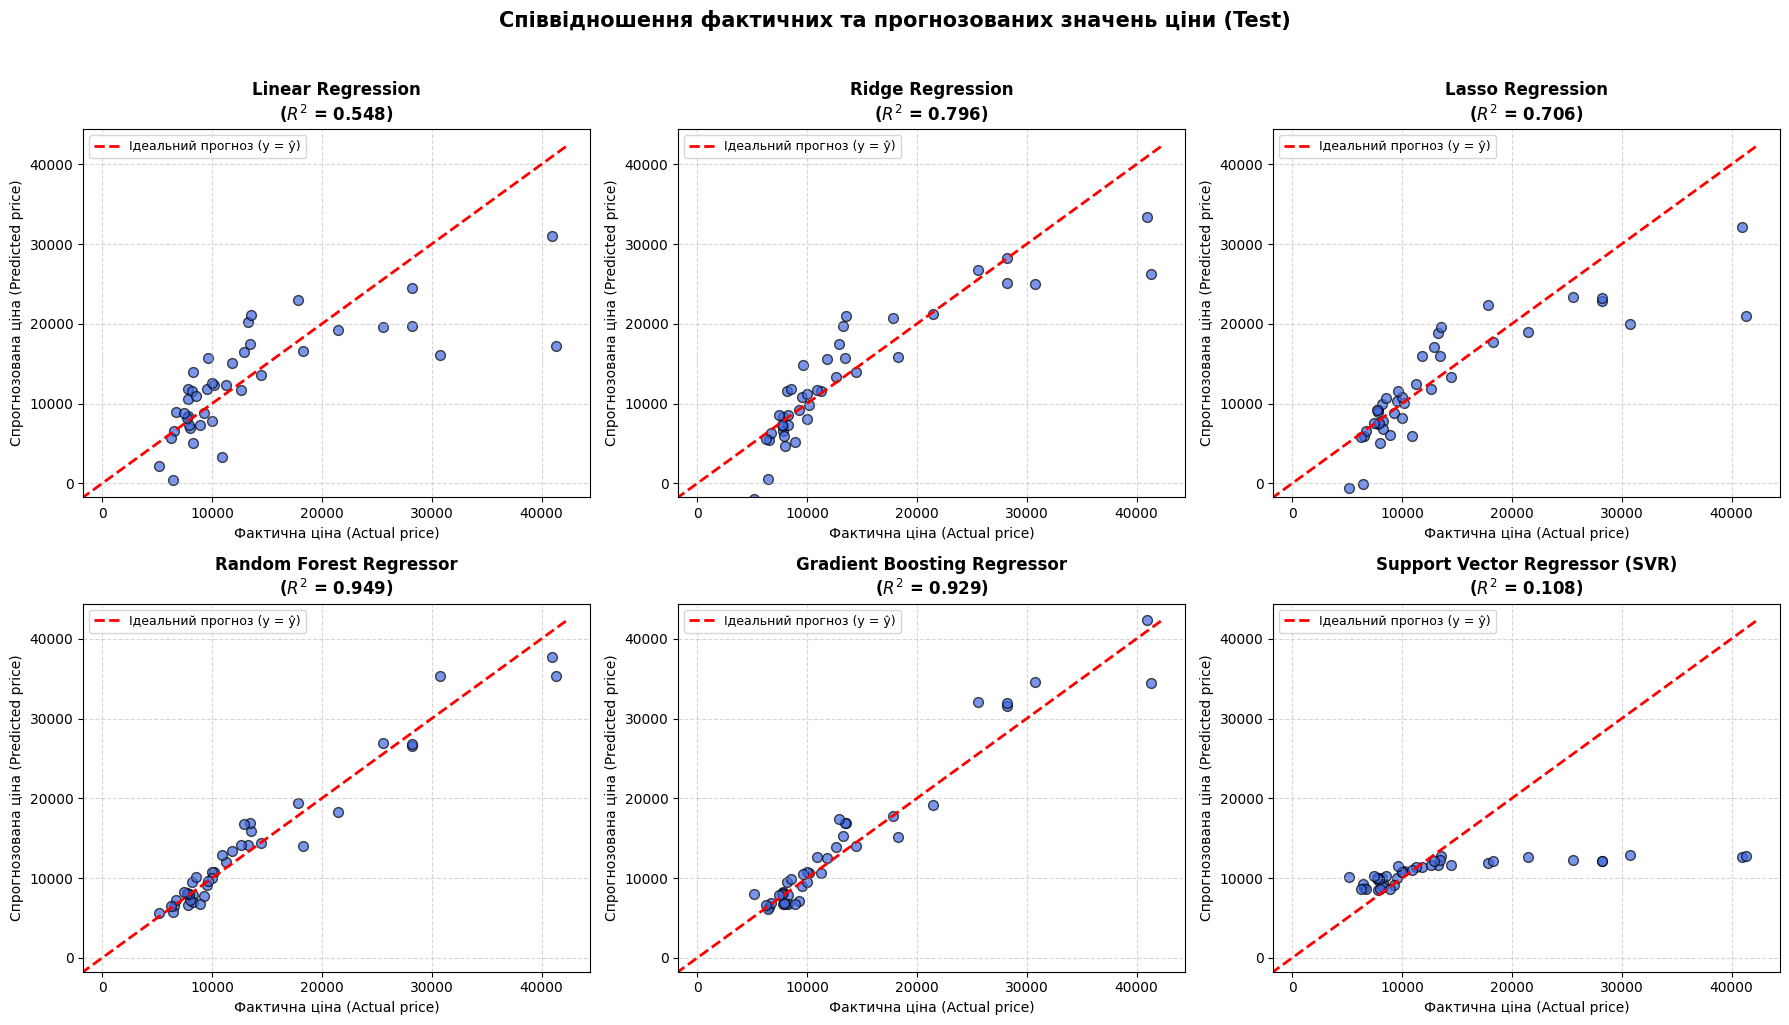

In [34]:
from sklearn.metrics import r2_score

# Налаштовуємо сітку графіків 2x3 для 6 моделей
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

# Визначаємо спільні межі для лінії ідеального прогнозу (y = y_pred)
min_val = min(y_test.min(), min([pipe.predict(X_test).min() for pipe in pipelines.values()]))
max_val = max(y_test.max(), max([pipe.predict(X_test).max() for pipe in pipelines.values()]))

for idx, (name, pipe) in enumerate(pipelines.items()):
    # Прогноз моделі на тесті
    y_pred = pipe.predict(X_test)
    r2 = r2_score(y_test, y_pred)

    # Точковий графік: фактичні значення проти прогнозованих
    axes[idx].scatter(y_test, y_pred, alpha=0.7, color='royalblue', edgecolors='k', s=50)

    # Червона пунктирна лінія ідеального прогнозу (Actual == Predicted)
    axes[idx].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ідеальний прогноз (y = ŷ)')

    axes[idx].set_title(f"{name}\n($R^2$ = {r2:.3f})", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Фактична ціна (Actual price)', fontsize=10)
    axes[idx].set_ylabel('Спрогнозована ціна (Predicted price)', fontsize=10)
    axes[idx].set_xlim(min_val * 0.9, max_val * 1.05)
    axes[idx].set_ylim(min_val * 0.9, max_val * 1.05)
    axes[idx].grid(True, linestyle='--', alpha=0.5)
    axes[idx].legend(loc='upper left', fontsize=9)

plt.suptitle('Співвідношення фактичних та прогнозованих значень ціни (Test)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [35]:
# 1. Обираємо 10 випадкових спостережень з тестової вибірки
sample_test_X = X_test.sample(n=10, random_state=42)
sample_test_y = y_test.loc[sample_test_X.index]
sample_car_ids = car_id_test.loc[sample_test_X.index]

# 2. Отримуємо навчений пайплайн Random Forest
rf_pipeline = pipelines['Random Forest Regressor']

# 3. Формуємо прогноз
y_pred_sample = rf_pipeline.predict(sample_test_X)

# 4. Розрахунок помилок
abs_error = np.abs(sample_test_y.values - y_pred_sample)
abs_pct_error = (abs_error / sample_test_y.values) * 100

# 5. Формування підсумкової таблиці
comparison_10_df = pd.DataFrame({
    'car_ID': sample_car_ids.values,
    'Фактична ціна': sample_test_y.values,
    'Прогнозована ціна': y_pred_sample,
    'Абсолютна помилка ($)': abs_error,
    'Абсолютна відсоткова помилка (%)': abs_pct_error
})

# Форматування виводу для наочності
styled_10_df = comparison_10_df.style.format({
    'Фактична ціна': '${:,.2f}',
    'Прогнозована ціна': '${:,.2f}',
    'Абсолютна помилка ($)': '${:,.2f}',
    'Абсолютна відсоткова помилка (%)': '{:.2f}%'
})

print("Результати прогнозу для 10 випадкових авто з тестової вибірки")
display(styled_10_df)

# Середня похибка на обраній вибірці
print(f"\nСередня абсолютна помилка (MAE): ${abs_error.mean():,.2f}")
print(f"Середня відсоткова помилка (MAPE): {abs_pct_error.mean():.2f}%")

Результати прогнозу для 10 випадкових авто з тестової вибірки


,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка ($),Абсолютна відсоткова помилка (%)
0,26,"$6,692.00","$7,298.81",$606.81,9.07%
1,176,"$9,988.00","$10,798.65",$810.65,8.12%
2,148,"$10,198.00","$10,714.57",$516.57,5.07%
3,17,"$41,315.00","$35,310.69","$6,004.31",14.53%
4,69,"$28,248.00","$26,595.28","$1,652.72",5.85%
5,147,"$7,463.00","$8,230.00",$767.00,10.28%
6,144,"$9,960.00","$10,065.20",$105.20,1.06%
7,85,"$14,489.00","$14,346.48",$142.52,0.98%
8,195,"$12,940.00","$16,765.65","$3,825.65",29.56%
9,160,"$7,788.00","$7,995.56",$207.56,2.67%



Середня абсолютна помилка (MAE): $1,463.90
Середня відсоткова помилка (MAPE): 8.72%


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Підсумкові висновки:
+ Якість моделей та найкращий результат: Найкращу точність показали ансамблеві алгоритми (Gradient Boosting Regressor та Random Forest Regressor). Вони досягли найвищого значення детермінації (R2 близько 0.90) та мінімальних похибок із середньою відносною помилкою (MAPE) на рівні 8–11%. Лінійні моделі з регуляризацією (Ridge, Lasso) продемонстрували стабільні результати, але поступилися ансамблям у вловлюванні нелінійних залежностей.   

+ Аналіз похибок та перенавчання: Основна абсолютна похибка зосереджена в преміальному сегменті: моделі дещо недооцінюють найдорожчі рідкісні авто через малу кількість таких прикладів у навчальній вибірці. Явних ознак критичного перенавчання не виявлено завдяки видаленню взаємопов'язаних ознак та використанню регуляризації.   

+ Вплив передобробки: Застосування вінзоризації викидів (clipping) вберегло невеликий набір даних від втрати рядків. Перетворення Йео–Джонсона успішно нормалізувало скошені розподіли, а побудова єдиного Pipeline на базі тренувальної вибірки гарантувала повну відсутність витоку даних (data leakage) під час оцінювання на тесті.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
